# 02 · Exploratory analysis and statistical tests

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryam843/uk-road-accident-analytics/blob/main/notebooks/02_eda_and_tests.ipynb)

Questions:
1. When do collisions happen (hour × weekday, month), and how did the total change from 2005 to 2019?
2. How does the share of collisions that are **KSI** (killed or seriously injured) vary with light,
   speed limit, road type and urban/rural setting?
3. Which of those associations are large enough to matter? (effect sizes, not just p-values)
4. A count model for daily collisions: Poisson GLM, checked for overdispersion.

KSI shares are shown both **as reported** and **adjusted for changes in police severity reporting
(DfT)**. From 2016 many forces moved to injury-based reporting (CRASH/COPA), which records more
injuries as serious. The adjusted share uses DfT's per-record adjustment probabilities
(`collision_adjusted_serious`), so years before and after the change can be compared.

All figures are saved to `reports/figures/`. Results: **TBD (run notebooks/02_eda_and_tests.ipynb)**.

In [ ]:
# Setup: works from the repo root, from notebooks/, or on Google Colab.
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src/config.py").exists():
    if not Path("uk-road-accident-analytics").exists():
        !git clone -q https://github.com/maryam843/uk-road-accident-analytics.git
    %cd uk-road-accident-analytics
    %pip install -q -r requirements.txt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [ ]:
import logging

import matplotlib.pyplot as plt
import pandas as pd

from src import clean, config, evaluate

config.setup_logging(logging.INFO)
evaluate.apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

DATA_DIR = config.get_data_dir()
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
if not (PROCESSED / config.COLLISIONS_PARQUET).exists():
    # Fresh runtime (e.g. Colab): download (several GB) and clean. Takes a while, once.
    from src import download

    download.main([])
    clean.run()
print("DATA_DIR =", DATA_DIR)

DATA_DIR = data


In [ ]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

COLUMNS = ["collision_index", "collision_year", "date", "hour", "collision_severity", "ksi",
           "collision_adjusted_serious", "light_conditions_label", "weather_conditions_label",
           "road_type_label", "speed_limit", "urban_or_rural_area_label", "number_of_vehicles"]
df = pd.read_parquet(PROCESSED / config.COLLISIONS_PARQUET, columns=COLUMNS)
# Adjusted KSI per collision: 1 for fatal, otherwise DfT's probability of being serious.
df["ksi_adjusted"] = np.where(df["collision_severity"] == 1, 1.0,
                              df["collision_adjusted_serious"].astype(float))
df["weekday"] = pd.Categorical(df["date"].dt.day_name(), categories=[
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], ordered=True)
print(f"{len(df):,} collisions, {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"KSI share (as reported): {df['ksi'].mean():.4f}; adjusted: {df['ksi_adjusted'].mean():.4f}")

2,287,427 collisions, 2005-01-01 to 2019-12-31
KSI share (as reported): 0.1580; adjusted: 0.2079


## 1. When do collisions happen?

17:17:31 INFO src.evaluate: Saved figure reports/figures/02_heatmap_hour_weekday.png


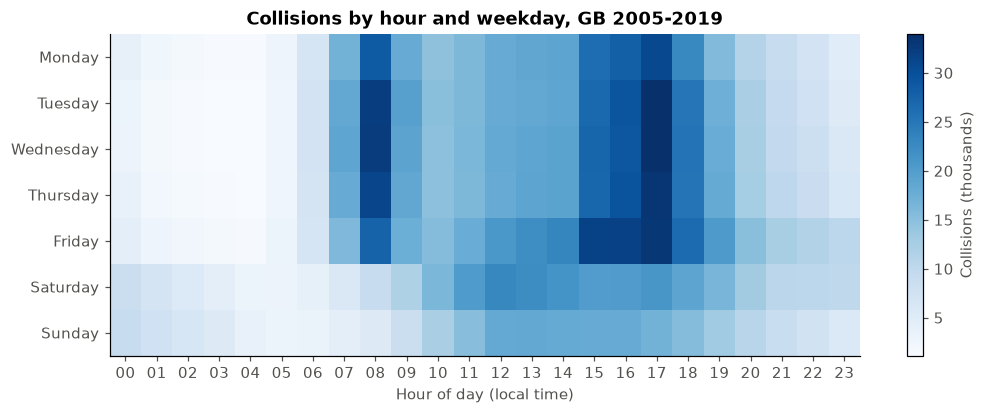

In [ ]:
heat = (df.dropna(subset=["hour"]).groupby(["weekday", "hour"], observed=False).size()
        .unstack("hour").fillna(0))
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat / 1000, aspect="auto", cmap=evaluate.SEQUENTIAL_CMAP)
ax.set_xticks(range(24), [f"{h:02d}" for h in range(24)])
ax.set_yticks(range(7), heat.index)
ax.set_xlabel("Hour of day (local time)")
ax.set_title("Collisions by hour and weekday, GB 2005-2019")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Collisions (thousands)")
evaluate.save_fig(fig, "02_heatmap_hour_weekday")
plt.show()

17:17:31 INFO src.evaluate: Saved figure reports/figures/02_monthly_seasonality.png


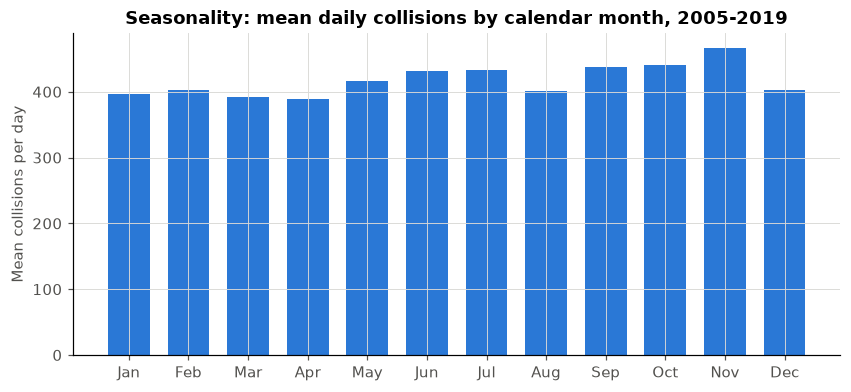

,1,2,3,4,5,6,7,8,9,10,11,12
mean_collisions_per_day,396.753,402.262,392.434,389.453,416.778,431.747,432.604,401.697,437.184,441.305,465.751,403.178


In [ ]:
daily = df.groupby(df["date"].dt.normalize()).size()
daily = daily.reindex(pd.date_range(f"{config.YEAR_MIN}-01-01", f"{config.YEAR_MAX}-12-31"),
                      fill_value=0)
per_day_by_month = daily.groupby(daily.index.month).mean()
MONTH_ABBR = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(per_day_by_month.index, per_day_by_month.values, width=0.7)
ax.set_xticks(range(1, 13), MONTH_ABBR)
ax.set_ylabel("Mean collisions per day")
ax.set_title("Seasonality: mean daily collisions by calendar month, 2005-2019")
evaluate.save_fig(fig, "02_monthly_seasonality")
plt.show()
display(per_day_by_month.rename("mean_collisions_per_day").to_frame().T)

17:17:32 INFO src.evaluate: Saved figure reports/figures/02_trend_collisions_and_ksi_share.png


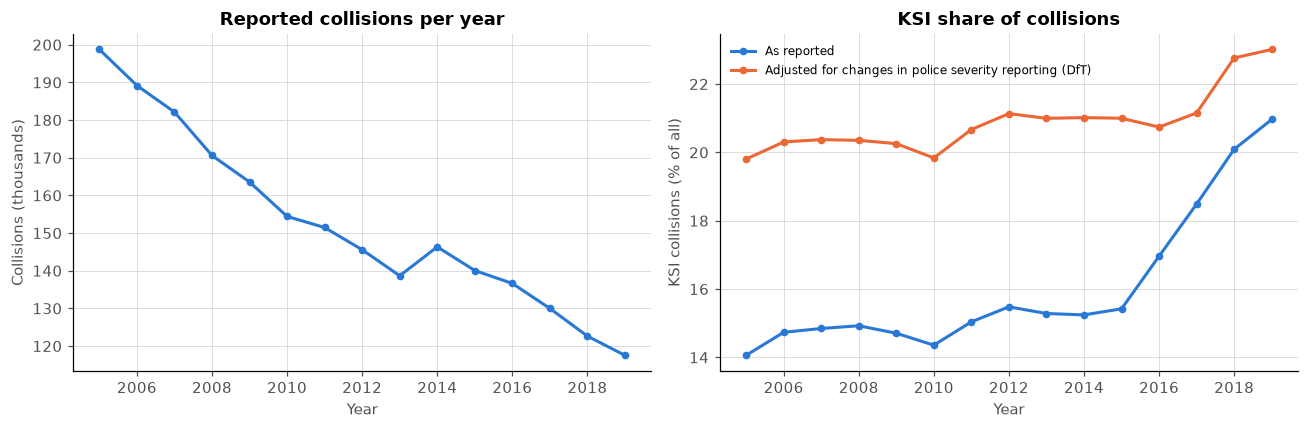

,collisions,ksi_share,ksi_share_adjusted
collision_year,,,
2005,198735,0.141,0.198
2006,189161,0.147,0.203
2007,182115,0.148,0.204
2008,170591,0.149,0.204
2009,163554,0.147,0.203
2010,154414,0.144,0.198
2011,151474,0.150,0.207
2012,145571,0.155,0.211
2013,138660,0.153,0.210


In [ ]:
yearly = df.groupby("collision_year").agg(collisions=("ksi", "size"), ksi_share=("ksi", "mean"),
                                         ksi_share_adjusted=("ksi_adjusted", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(yearly.index, yearly["collisions"] / 1000, marker="o", markersize=4)
axes[0].set_title("Reported collisions per year")
axes[0].set_ylabel("Collisions (thousands)")
axes[0].set_xlabel("Year")
axes[1].plot(yearly.index, 100 * yearly["ksi_share"], marker="o", markersize=4, label="As reported")
axes[1].plot(yearly.index, 100 * yearly["ksi_share_adjusted"], marker="o", markersize=4,
             label="Adjusted for changes in police severity reporting (DfT)")
axes[1].set_title("KSI share of collisions")
axes[1].set_ylabel("KSI collisions (% of all)")
axes[1].set_xlabel("Year")
axes[1].legend(fontsize=8)
fig.tight_layout()
evaluate.save_fig(fig, "02_trend_collisions_and_ksi_share")
plt.show()
display(yearly)

## 2. KSI share by road and light conditions

17:17:34 INFO src.evaluate: Saved figure reports/figures/02_ksi_share_by_condition.png


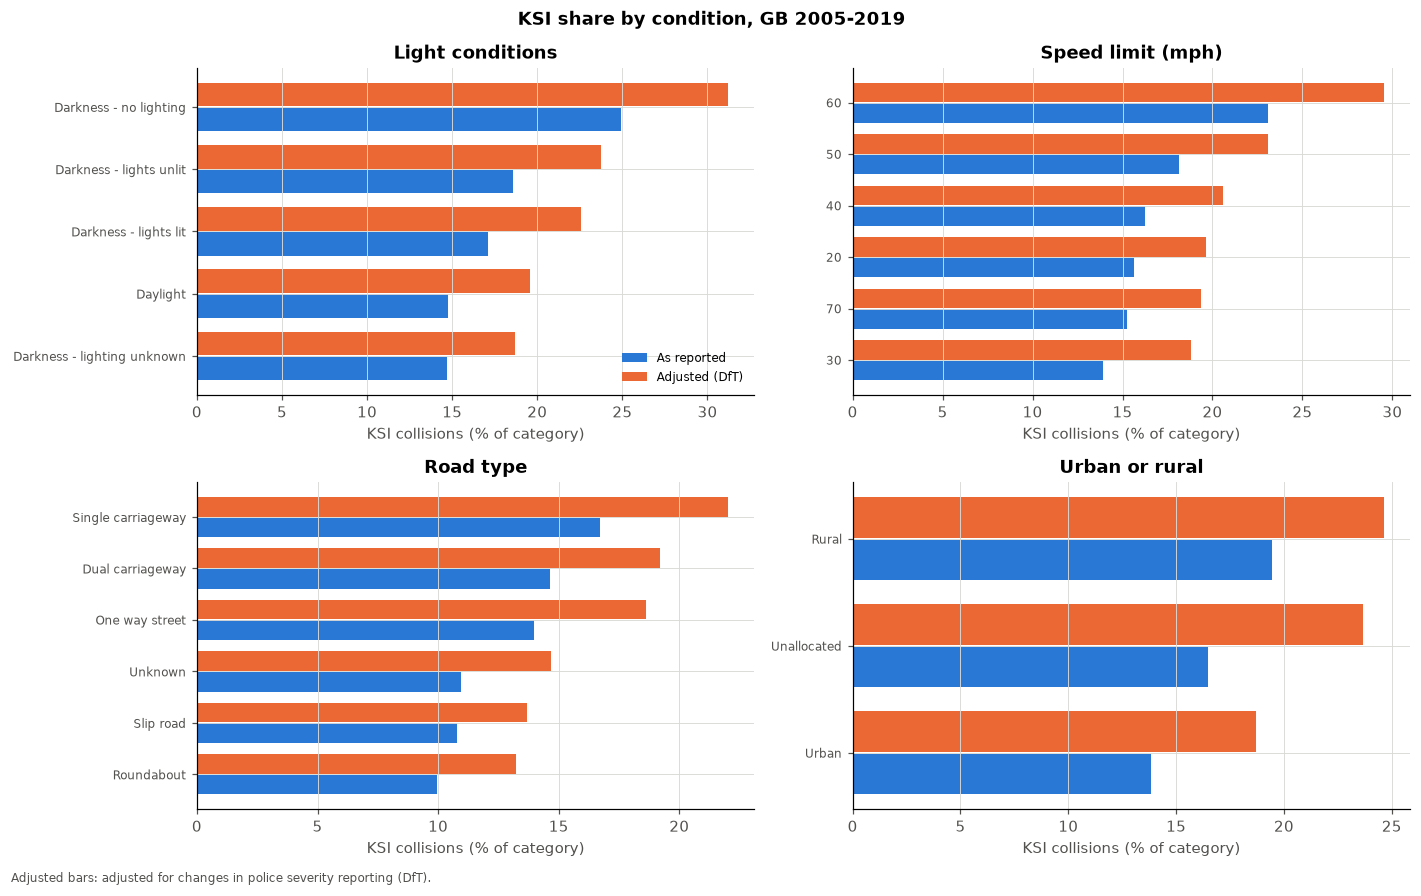

Light conditions


,n,ksi_share,ksi_share_adjusted
light_conditions_label,,,
Darkness - lighting unknown,29473,0.147,0.187
Daylight,1668067,0.148,0.195
Darkness - lights lit,453297,0.171,0.226
Darkness - lights unlit,11719,0.186,0.237
Darkness - no lighting,124856,0.249,0.312


Speed limit (mph)


,n,ksi_share,ksi_share_adjusted
speed_limit,,,
30,1448958,0.139,0.188
70,162284,0.152,0.194
20,60807,0.156,0.197
40,188607,0.163,0.206
50,79248,0.181,0.231
60,347370,0.231,0.295


Road type


,n,ksi_share,ksi_share_adjusted
road_type_label,,,
Roundabout,151207,0.100,0.132
Slip road,25005,0.108,0.137
Unknown,18931,0.110,0.147
One way street,49288,0.140,0.186
Dual carriageway,341470,0.146,0.192
Single carriageway,1701525,0.167,0.220


Urban or rural


,n,ksi_share,ksi_share_adjusted
urban_or_rural_area_label,,,
Urban,1484455,0.138,0.187
Unallocated,243,0.165,0.237
Rural,802728,0.195,0.246


In [ ]:
def ksi_share_by(column):
    """n, KSI share as reported, and adjusted KSI share for each category of a column."""
    out = df.groupby(column, observed=True).agg(
        n=("ksi", "size"), ksi_share=("ksi", "mean"), ksi_share_adjusted=("ksi_adjusted", "mean"))
    return out.sort_values("ksi_share_adjusted")


BREAKDOWNS = {"light_conditions_label": "Light conditions", "speed_limit": "Speed limit (mph)",
              "road_type_label": "Road type", "urban_or_rural_area_label": "Urban or rural"}
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
tables = {}
for ax, (col, title) in zip(axes.ravel(), BREAKDOWNS.items(), strict=True):
    t = ksi_share_by(col)
    t = t[t["n"] >= 100]  # hide tiny categories (still listed in the tables below)
    tables[title] = ksi_share_by(col)
    y = np.arange(len(t))
    ax.barh(y - 0.2, 100 * t["ksi_share"], height=0.38, label="As reported")
    ax.barh(y + 0.2, 100 * t["ksi_share_adjusted"], height=0.38, label="Adjusted (DfT)")
    ax.set_yticks(y, [str(i) for i in t.index], fontsize=8)
    ax.set_xlabel("KSI collisions (% of category)")
    ax.set_title(title)
axes[0, 0].legend(fontsize=8)
fig.suptitle("KSI share by condition, GB 2005-2019", fontweight="bold")
fig.text(0.01, -0.01, f"Adjusted bars: {config.SEVERITY_ADJUSTED_FOOTNOTE}.", fontsize=8, color="#52514e")
fig.tight_layout()
evaluate.save_fig(fig, "02_ksi_share_by_condition")
plt.show()
for title, t in tables.items():
    print(title)
    display(t)

## 3. Statistical tests with effect sizes

With millions of collisions, almost any difference is "statistically significant": p-values
will be tiny even for associations too weak to matter. So each test is reported with an
**effect size**, and the effect size is what gets interpreted:

- **Chi-square + Cramér's V** for KSI × category (0.1 small, 0.3 medium, 0.5 large).
- **Welch t-test + Cohen's d** for a numeric variable in KSI vs non-KSI collisions (0.2 / 0.5 / 0.8).
- **One-way ANOVA + eta-squared** for daily collision counts across groups (0.01 / 0.06 / 0.14).

The labels are Cohen's rough conventions, not thresholds. The tests use the as-reported KSI
label, so the 2016+ reporting change adds some noise to every severity association.

In [ ]:
chi_rows = []
for col, title in {"light_conditions_label": "Light conditions",
                   "weather_conditions_label": "Weather", "road_type_label": "Road type"}.items():
    table = pd.crosstab(df[col], df["ksi"])  # NaN categories are excluded
    chi2, p, v, dof = evaluate.cramers_v(table)
    chi_rows.append({"variable": title, "n": int(table.to_numpy().sum()), "chi2": chi2, "dof": dof,
                     "p_value": p, "cramers_v": v, "effect": evaluate.describe_effect(v, "cramers_v")})
chi_table = pd.DataFrame(chi_rows)
display(chi_table.style.format({"n": "{:,}", "chi2": "{:,.1f}", "p_value": "{:.2e}",
                                "cramers_v": "{:.3f}"}))

,variable,n,chi2,dof,p_value,cramers_v,effect
0,Light conditions,"2,287,412","9,789.9",4,0.00e+00,0.065,negligible
1,Weather,"2,287,233","2,270.8",8,0.00e+00,0.032,negligible
2,Road type,"2,287,426","6,246.8",5,0.00e+00,0.052,negligible


In [ ]:
t_rows = []
for col, title in {"speed_limit": "Speed limit (mph)", "number_of_vehicles": "Vehicles involved"}.items():
    sub = df[[col, "ksi"]].dropna()
    a = sub.loc[sub["ksi"] == 1, col].astype(float)
    b = sub.loc[sub["ksi"] == 0, col].astype(float)
    t, p = stats.ttest_ind(a, b, equal_var=False)
    d = evaluate.cohens_d(a, b)
    t_rows.append({"variable": title, "mean_ksi": a.mean(), "mean_non_ksi": b.mean(), "welch_t": t,
                   "p_value": p, "cohens_d": d, "effect": evaluate.describe_effect(d, "cohens_d")})
display(pd.DataFrame(t_rows).style.format({"mean_ksi": "{:.2f}", "mean_non_ksi": "{:.2f}",
                                           "welch_t": "{:,.1f}", "p_value": "{:.2e}",
                                           "cohens_d": "{:.3f}"}))

,variable,mean_ksi,mean_non_ksi,welch_t,p_value,cohens_d,effect
0,Speed limit (mph),40.78,38.25,94.9,0.00e+00,0.179,negligible
1,Vehicles involved,1.70,1.86,-111.1,0.00e+00,-0.219,small


In [ ]:
daily_frame = daily.rename("n").to_frame()
daily_frame["weekday"] = daily_frame.index.day_name()
daily_frame["month"] = daily_frame.index.month
daily_frame["year"] = daily_frame.index.year
a_rows = []
for col, title in {"weekday": "Weekday", "month": "Calendar month"}.items():
    groups = [g["n"].to_numpy() for _, g in daily_frame.groupby(col)]
    f, p = stats.f_oneway(*groups)
    eta = evaluate.eta_squared(groups)
    a_rows.append({"daily collisions by": title, "F": f, "p_value": p, "eta_squared": eta,
                   "effect": evaluate.describe_effect(eta, "eta_squared")})
display(pd.DataFrame(a_rows).style.format({"F": "{:,.1f}", "p_value": "{:.2e}",
                                           "eta_squared": "{:.3f}"}))

,daily collisions by,F,p_value,eta_squared,effect
0,Weekday,248.0,2.53e-281,0.214,large
1,Calendar month,26.8,3.23e-55,0.051,small


Interpretation: **TBD (run notebooks/02_eda_and_tests.ipynb)**. Read the `effect` columns,
not the p-values.

## 4. Count model for daily collisions

`daily collisions ~ year + month + weekday`, with all three as categorical. Daily counts
are counts, so the model is a Poisson GLM rather than OLS. OLS on integer-coded categories
would treat the DfT weekday codes (1 = Sunday … 7 = Saturday) as amounts, as if Saturday were
"seven times" Sunday.

A Poisson model assumes variance = mean. The dispersion statistic (Pearson χ² / residual df)
checks that. If it is above 1.5, the counts are overdispersed: Poisson standard errors would
be too small, so the model switches to a **Negative Binomial** (NB2), which estimates an extra
dispersion parameter α.

Results are reported as **incidence rate ratios** (IRR = exp(coef)) with 95% CIs. An IRR of
1.10 for Friday means about 10% more collisions per day than the reference day (Monday),
holding year and month fixed.

In [ ]:
formula = ("n ~ C(year) + C(month) + C(weekday, Treatment(reference='Monday'))")
poisson = smf.glm(formula, data=daily_frame, family=sm.families.Poisson()).fit()
dispersion = poisson.pearson_chi2 / poisson.df_resid
print(f"Poisson dispersion (Pearson chi2 / df) = {dispersion:.2f}")
if dispersion > 1.5:
    model = smf.negativebinomial(formula, data=daily_frame).fit(disp=0, maxiter=500)
    print(f"Overdispersed -> Negative Binomial (NB2), alpha = {model.params['alpha']:.4f}")
    model_name = "Negative Binomial"
else:
    model = poisson
    model_name = "Poisson"
print(f"Model used: {model_name}; AIC = {model.aic:,.1f} (Poisson AIC = {poisson.aic:,.1f})")

Poisson dispersion (Pearson chi2 / df) = 7.86


Overdispersed -> Negative Binomial (NB2), alpha = 0.0181
Model used: Negative Binomial; AIC = 60,222.3 (Poisson AIC = 87,465.3)


In [ ]:
params = model.params.drop("alpha", errors="ignore")
ci = model.conf_int().loc[params.index]
irr = pd.DataFrame({"IRR": np.exp(params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                    "p_value": model.pvalues.loc[params.index]})
irr.index = (irr.index.str.replace("C(weekday, Treatment(reference='Monday'))", "weekday", regex=False)
             .str.replace("C(month)", "month", regex=False).str.replace("C(year)", "year", regex=False))
display(irr.style.format({"IRR": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}",
                          "p_value": "{:.2e}"}))

,IRR,ci_low,ci_high,p_value
Intercept,512.714,501.935,523.726,0.00e+00
year[T.2006],0.952,0.933,0.972,2.75e-06
year[T.2007],0.918,0.899,0.937,3.09e-16
year[T.2008],0.857,0.840,0.875,5.78e-49
year[T.2009],0.823,0.806,0.840,4.43e-77
year[T.2010],0.776,0.760,0.792,2.18e-128
year[T.2011],0.762,0.746,0.778,2.30e-147
year[T.2012],0.730,0.715,0.746,2.63e-195
year[T.2013],0.695,0.681,0.710,3.93e-259
year[T.2014],0.736,0.721,0.751,4.72e-186


17:17:39 INFO src.evaluate: Saved figure reports/figures/02_count_model_irr.png


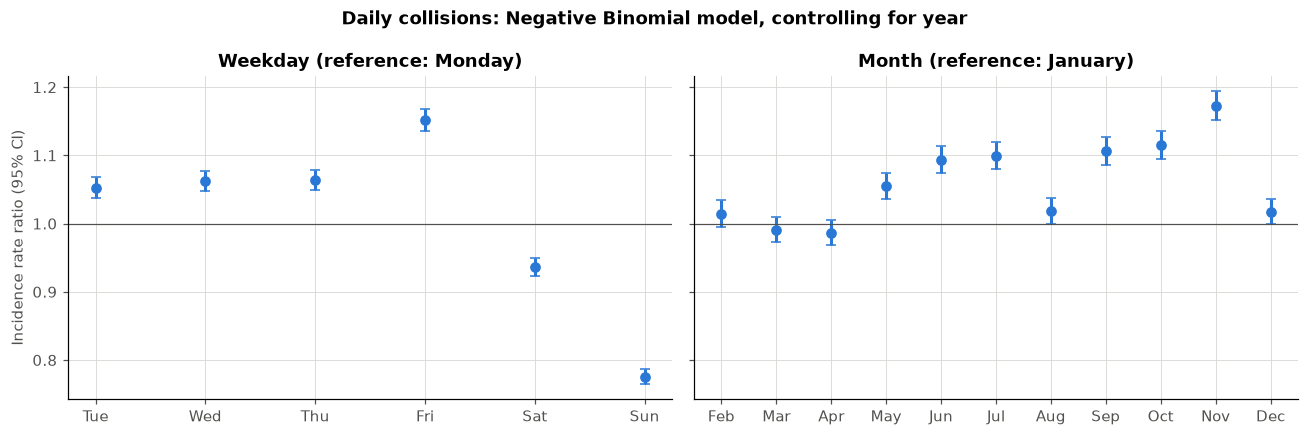

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, prefix, title in [(axes[0], "weekday", "Weekday (reference: Monday)"),
                          (axes[1], "month", "Month (reference: January)")]:
    part = irr[irr.index.str.startswith(prefix)].copy()
    part["level"] = part.index.str.extract(r"\[T\.(.*)\]")[0].to_numpy()
    if prefix == "weekday":
        order = ["Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
        part = part.set_index("level").reindex(order)
        labels = [d[:3] for d in order]
    else:
        part = part.set_index("level").sort_index(key=lambda s: s.astype(int))
        labels = [MONTH_ABBR[int(m) - 1] for m in part.index]
    x = np.arange(len(part))
    ax.errorbar(x, part["IRR"], yerr=[part["IRR"] - part["ci_low"], part["ci_high"] - part["IRR"]],
                fmt="o", markersize=6, capsize=3)
    ax.axhline(1, color="#52514e", linewidth=0.8)
    ax.set_xticks(x, labels)
    ax.set_title(title)
axes[0].set_ylabel("Incidence rate ratio (95% CI)")
fig.suptitle(f"Daily collisions: {model_name} model, controlling for year", fontweight="bold")
fig.tight_layout()
evaluate.save_fig(fig, "02_count_model_irr")
plt.show()

Interpretation: **TBD (run notebooks/02_eda_and_tests.ipynb)**.